# RAG over the FMLA Employer's Guide: Baseline Retrieval vs. Cross-Encoder Re-Ranking

**Document:** *The Employer's Guide to the Family and Medical Leave Act* (U.S. Department of Labor, 76 pages), `data/GOVPUB-L-PURL-gpo84393.pdf`

**Two pipelines over the same chunks:**
- **Pipeline 1 (baseline):** bi-encoder retrieves the top 10 chunks, the top 3 go to the LLM, giving Answer 1.
- **Pipeline 2 (re-ranking):** the same top 10 are re-scored by a cross-encoder, the new top 3 go to the LLM with the same prompt, giving Answer 2.

**Notebook layout:**
1. Setup
2. Loading and cleaning the PDF
3. Chunking
4. Embeddings and vector store
5. Pipeline 1
6. Pipeline 2
7. Failure-mode analysis
8. Latency
9. Scaling

## Step 1: Setup

Install the packages, import them, and check that the Gemini API key works.

- The retrieval models (bi-encoder and cross-encoder) run locally on the CPU.
- Only the answer generation calls the Gemini API.

In [1]:
# Install packages into the same environment this notebook runs in (%pip, not !pip).
# torch comes from PyTorch's CPU-only index: this laptop has no GPU, and the default
# CUDA build is several GB (the first install attempt timed out downloading it).
%pip install -q --no-cache-dir --default-timeout=120 torch --index-url https://download.pytorch.org/whl/cpu
%pip install -q --no-cache-dir --default-timeout=120 -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import platform

import numpy as np
import pandas as pd
import torch
import pymupdf                 # PyMuPDF: extracts text from the PDF
import faiss                   # vector index for similarity search
import sentence_transformers
from sentence_transformers import SentenceTransformer, CrossEncoder
from google import genai
from google.genai import types
from dotenv import load_dotenv

# Record the environment so the results can be reproduced later
print("python               ", platform.python_version())
print("torch                ", torch.__version__, "| CUDA available:", torch.cuda.is_available())
print("CPU threads used     ", torch.get_num_threads())
print("pymupdf              ", pymupdf.__version__)
print("faiss                ", faiss.__version__)
print("sentence-transformers", sentence_transformers.__version__)
print("numpy / pandas       ", np.__version__, "/", pd.__version__)

python                3.12.3
torch                 2.14.1+cpu | CUDA available: False
CPU threads used      10
pymupdf               1.28.2
faiss                 1.15.1
sentence-transformers 6.1.0
numpy / pandas        2.4.3 / 3.0.1


In [3]:
# Paths used throughout the notebook
DATA_PDF = "data/GOVPUB-L-PURL-gpo84393.pdf"
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

assert os.path.exists(DATA_PDF), "PDF not found - run the notebook from the repo root"
print("PDF size: %.1f MB" % (os.path.getsize(DATA_PDF) / 1e6))

PDF size: 5.2 MB


In [4]:
# The API key lives in .env (never committed; see .gitignore).
# load_dotenv() copies the lines of .env into environment variables.
load_dotenv()
api_key = os.getenv("GEMINI_API_KEY")
assert api_key, "GEMINI_API_KEY missing - add it to a .env file in the repo root"

# Retry automatically on temporary server errors (429 rate limit, 503 "high demand", other 5xx),
# waiting about 2 s, 4 s, 8 s, ... between attempts. Both kinds of error happened while building this.
client = genai.Client(
    api_key=api_key,
    http_options=types.HttpOptions(
        retry_options=types.HttpRetryOptions(attempts=6, initial_delay=2.0, max_delay=60.0)),
)

# Model names change over time, so list the Flash models this key can call
# (speech "tts" and "image" models are skipped: we only need text answers)
flash_models = [
    m.name for m in client.models.list()
    if "flash" in m.name and "generateContent" in (m.supported_actions or [])
    and "tts" not in m.name and "image" not in m.name
]
print(len(flash_models), "Flash models available:")
for name in flash_models:
    print("  ", name)

14 Flash models available:
   models/gemini-2.5-flash
   models/gemini-flash-latest
   models/gemini-flash-lite-latest
   models/gemini-2.5-flash-lite
   models/gemini-3-flash-preview
   models/gemini-3.1-flash-lite-preview
   models/gemini-3.1-flash-lite
   models/gemini-3.5-flash
   models/gemini-3.5-flash-lite
   models/gemini-omni-flash-preview
   models/gemini-omni-1.1-flash
   models/gemini-3.6-flash
   models/gemini-3.7-flash
   models/gemini-3.8-flash


In [5]:
import json
import time

# One model for the whole notebook, so both pipelines use exactly the same LLM.
# gemini-3.8-flash allows only 20 free requests per day, which is not enough for this
# assignment, so we use gemini-3.5-flash-lite (separate free quota, and faster).
# (gemini-2.5-flash is no longer offered to new API keys.)
GEMINI_MODEL = "gemini-3.5-flash-lite"
assert "models/" + GEMINI_MODEL in flash_models, "model not available for this key"

# Smoke test: one tiny request to confirm the key and model work. The result is saved, so
# re-running the notebook does not spend free-tier quota on it again.
SMOKE_PATH = os.path.join(RESULTS_DIR, "smoke_test.json")
smoke = json.load(open(SMOKE_PATH)) if os.path.exists(SMOKE_PATH) else {}
if smoke.get("model") != GEMINI_MODEL:
    start = time.perf_counter()
    reply = client.models.generate_content(
        model=GEMINI_MODEL,
        contents="Say hello in five words.",
        config=types.GenerateContentConfig(temperature=0),
    )
    usage = reply.usage_metadata
    smoke = {"model": GEMINI_MODEL, "reply": reply.text.strip(),
             "seconds": round(time.perf_counter() - start, 1),
             "prompt_tokens": usage.prompt_token_count,
             "answer_tokens": usage.candidates_token_count,
             "thinking_tokens": usage.thoughts_token_count}
    with open(SMOKE_PATH, "w") as f:
        json.dump(smoke, f, indent=2)

for name, value in smoke.items():
    print(f"{name:15}: {value}")

model          : gemini-3.5-flash-lite
reply          : Hello, how are you today?
seconds        : 0.9
prompt_tokens  : 7
answer_tokens  : 7
thinking_tokens: None


## Step 2: Loading and cleaning the PDF

PyMuPDF gives every piece of text with its position and font. We use those signals to keep only real content:

- **Skip** the cover, disclaimer and table of contents (pp. 1-5), a full-page flowchart (p. 8), the index (pp. 72-75) and the back cover (p. 76).
- **Drop** the running header (above y = 90 pt) and footer (below y = 748 pt). The chapter name is read from the header first, because it exists only there.
- **Drop** comic speech bubbles and diagram labels (condensed fonts, 9 pt text, or tiny labels).
  - Known cost: the next-of-kin priority list on p. 42 exists only inside a diagram, so it is lost.
- **Keep** "DID YOU KNOW?" boxes, examples and footnotes. They hold the exceptions we want to test.
- **Very short blocks** (5 words or fewer) are not paragraphs on their own:
  - a sentence tail ("Defense.") is attached to the previous paragraph;
  - a label or lead-in ("Spouse", "DID YOU KNOW?", "The employer cannot refuse:") is attached to the next one.
- **Normalise** characters (ligatures, curly quotes, bullets).

Each paragraph keeps its page, chapter and section heading as metadata.

In [6]:
import re
import string
import unicodedata

# Pages without real content: cover, disclaimer and contents (1-5), full-page flowchart (8),
# index (72-75) and back cover (76)
SKIP_PAGES = {1, 2, 3, 4, 5, 8, 72, 73, 74, 75, 76}

# Pages are 612 x 792 pt and y grows downwards. The running header sits above y=90 and the
# footer below y=748; body text always lies in between (measured: y=115 to y=745).
HEADER_Y, FOOTER_Y = 90, 748


def is_illustration(span):
    """Comic speech bubbles and diagram labels use condensed fonts, 9 pt text or tiny labels;
    a few tables use huge (40 pt) 'X' symbols as tick marks."""
    return ("Cond" in span["font"] or 8.9 <= span["size"] <= 9.2
            or span["size"] < 7 or span["size"] > 24)


def clean_text(text):
    """Normalise characters so the text matches what a user would type."""
    text = unicodedata.normalize("NFKC", text)                   # ligature 'fi' -> 'f' + 'i'
    text = text.replace("\u2019", "'").replace("\u2018", "'")    # curly -> straight quotes
    text = text.replace("\u201c", '"').replace("\u201d", '"')
    text = re.sub(r"\u2022\s*", "\u2022 ", text)                 # bullet + tab -> bullet + space
    return re.sub(r"\s+", " ", text).strip()                     # line breaks -> single spaces


def read_chapter(page):
    """Read the chapter name from the running header, e.g. 'Chapter 2: When An Employee Needs FMLA Leave'."""
    spans = [s for b in page.get_text("dict", sort=True)["blocks"]
             for line in b.get("lines", []) for s in line["spans"]
             if s["text"].strip() and s["bbox"][1] < HEADER_Y]
    header = clean_text(" ".join(s["text"] for s in spans))
    title = clean_text(" ".join(s["text"] for s in spans if s["size"] >= 18))   # 20 pt title
    title = string.capwords(title.lower()).replace("Fmla", "FMLA")
    number = re.search(r"CHAPTER\s*(\d+)", header)
    return f"Chapter {number.group(1)}: {title}" if number else title

In [7]:
def block_to_text(block, removed):
    """Join the spans of one text block that survive the filters, line by line.

    Returns (text, largest font size), or (None, 0) if nothing in the block survives.
    `removed` counts the dropped spans by reason.
    """
    lines, max_size = [], 0
    for line in block.get("lines", []):
        parts = []
        for span in line["spans"]:
            if not span["text"].strip():          # whitespace-only span: keep as a separator
                parts.append(" ")
                continue
            if span["bbox"][1] < HEADER_Y or span["bbox"][1] > FOOTER_Y:
                removed["header/footer"] += 1
                continue
            if is_illustration(span):
                removed["illustration"] += 1
                continue
            parts.append(span["text"])
            max_size = max(max_size, span["size"])
        line_text = "".join(parts).strip()
        if line_text:
            lines.append(line_text)
    if not lines:
        return None, 0

    # Join the lines with spaces. A line ending in '-' ("FMLA-" + "protected") is joined without one.
    text = lines[0]
    for nxt in lines[1:]:
        text = text + nxt if text.endswith("-") else text + " " + nxt
    return clean_text(text), max_size

In [8]:
doc = pymupdf.open(DATA_PDF)
removed = {"header/footer": 0, "illustration": 0}
paragraphs = []
chapter, section = None, None
label = ""                # a short label / lead-in waiting to be glued to the next paragraph


def add_paragraph(page_no, text):
    paragraphs.append({"page": page_no, "chapter": chapter, "section": section, "text": text})


for page in doc:
    page_no = page.number + 1
    if page_no in SKIP_PAGES:
        continue

    page_chapter = read_chapter(page)            # read the header BEFORE it is dropped
    if page_chapter != chapter:                  # new chapter: text before its first heading
        chapter, section = page_chapter, page_chapter   # belongs to the chapter in general

    for block in page.get_text("dict", sort=True)["blocks"]:   # sort=True -> reading order
        text, size = block_to_text(block, removed)
        if text is None:
            continue

        # Section headings are 14-16 pt and not ALL CAPS ("DID YOU KNOW?" and the diagram
        # title "12 MONTH LOOK BACK" are capitals). Keep them as metadata, not as paragraphs.
        if 14 <= size <= 17 and not text.isupper():
            if label:                            # a dangling label stays as its own paragraph
                add_paragraph(page_no, label)
                label = ""
            section = text
            continue

        # Very short blocks (<= 5 words) are not paragraphs on their own
        if len(text.split()) <= 5:
            if text.endswith(".") and paragraphs:     # tail of the previous sentence
                paragraphs[-1]["text"] += " " + text
            else:                                     # label / lead-in for the next paragraph
                label = (label + " " + text).strip()
            continue

        if label:
            text, label = label + " " + text, ""
        add_paragraph(page_no, text)

paras = pd.DataFrame(paragraphs)
paras["n_words"] = paras["text"].str.split().str.len()

print(f"{len(paras)} paragraphs from {paras['page'].nunique()} pages, {paras['section'].nunique()} sections")
print("spans removed:", removed)
paras.head(8)

474 paragraphs from 65 pages, 100 sections
spans removed: {'header/footer': 326, 'illustration': 269}


,page,chapter,section,text,n_words
0,6,Introduction,Introduction,The Family and Medical Leave Act (FMLA) is a f...,50
1,6,Introduction,Introduction,• The birth of a son or daughter or placement ...,122
2,6,Introduction,Introduction,An eligible employee may also take up to 26 wo...,157
3,6,Introduction,Introduction,The U.S. Department of Labor's Wage and Hour D...,47
4,6,Introduction,Introduction,The Wage and Hour Division is committed to str...,110
5,6,Introduction,Introduction,The Department of Labor is providing this Guid...,92
6,7,Introduction,Introduction,Visit the Department's website for resources c...,12
7,7,Introduction,Introduction,• Key News • General Guidance • The Employee's...,47


In [9]:
# How much text did cleaning remove?
raw_words_all = sum(len(p.get_text().split()) for p in doc)
raw_words_kept_pages = sum(len(doc[int(p) - 1].get_text().split()) for p in paras["page"].unique())
print(f"words in the whole PDF          : {raw_words_all:6d}")
print(f"words on the pages we keep (raw): {raw_words_kept_pages:6d}")
print(f"words after cleaning            : {paras['n_words'].sum():6d}")

# Paragraphs and words per chapter
per_chapter = paras.groupby("chapter", sort=False).agg(
    pages=("page", "nunique"), paragraphs=("text", "size"), words=("n_words", "sum"))
display(per_chapter)

# Paragraph length distribution (in words): Step 3 builds chunks from these
print(paras["n_words"].describe().round(1).to_string())

words in the whole PDF          :  26537
words on the pages we keep (raw):  24454
words after cleaning            :  22319


,pages,paragraphs,words
chapter,,,
Introduction,2,8,637
Chapter 1: Covered Employers Under The FMLA And Their General Notice Requirements,5,38,1468
Chapter 2: When An Employee Needs FMLA Leave,9,61,3239
Chapter 3: Qualifying Reasons For Leave,5,38,1603
Chapter 4: The Certification Process,9,79,3008
Chapter 5: Military Family Leave,10,63,2726
Chapter 6: During An Employee's FMLA Leave,24,175,9281
Chapter 7: FMLA Prohibitions,1,12,357


count    474.0
mean      47.1
std       35.1
min        6.0
25%       19.0
50%       41.0
75%       63.0
max      212.0


In [10]:
# Sanity checks: the notebook stops here if cleaning went wrong
all_text = " ".join(paras["text"])

# The footer is the guide's title followed by the page number ("... Medical Leave Act 17").
# The title alone appears once as real content: page 7 lists it among the DoL resources.
assert not re.search(r"Medical Leave Act \d{1,2}\b", all_text), "footer left in"
assert all_text.count("The Employer's Guide to the Family and Medical Leave Act") == 1
assert not any(s in all_text for s in ["Bobby:", "Brenda (on phone)", "Jan 2015 Feb"]), "comic/diagram text left in"
assert not any(ch in all_text for ch in ["\u2018", "\u2019", "\u201c", "\u201d", "\ufb01"]), "special characters left in"

kept_pages = set(range(1, doc.page_count + 1)) - SKIP_PAGES
missing = kept_pages - set(paras["page"])
assert not missing, f"pages without any paragraph: {sorted(missing)}"
assert paras["chapter"].notna().all() and paras["section"].notna().all()

# Headings must be real section titles (no box titles, diagram titles or table symbols)
assert not any(s.isupper() or s.endswith(" X") for s in paras["section"].unique())

# We must not over-clean: the 'DID YOU KNOW?' box on page 17 has to survive, glued to its title
# (regex=False: in a regular expression the "?" would mean "the W is optional")
assert paras["text"].str.contains("DID YOU KNOW? An employer has the burden of showing", regex=False).any()
assert (paras["n_words"] > 5).all(), "short labels should have been merged"

print("all checks passed")

all checks passed


In [11]:
# Before / after for page 17
print("RAW (PyMuPDF default text, first 700 characters):\n")
print(doc[16].get_text()[:700])
print("\n" + "=" * 80 + "\nCLEANED paragraphs of page 17:\n")
for _, row in paras[paras["page"] == 17].iterrows():
    print(f"[{row['section']}]  {row['text'][:160]}{'...' if len(row['text']) > 160 else ''}\n")

RAW (PyMuPDF default text, first 700 characters):

The Employer’s Guide to the Family and Medical Leave Act
17
1,250 Hours of Service
The hours of service requirement will be met if an employee has worked a total of 1,250 hours of service 
in the 12 months immediately preceding the start of the FMLA leave. This averages to a little more than 24 
hours of work a week in the 12-month period.
•	 Generally, the principles for compensable hours of work under the Fair Labor Standards Act (FLSA) 
are used in determining the hours of service that an employee has worked. 
•	 Only the time actually worked, including overtime hours worked, is counted. Time not actually 
worked, including vacation, personal leave, sick leave, holidays, and any other for

CLEANED paragraphs of page 17:

[1,250 Hours of Service]  The hours of service requirement will be met if an employee has worked a total of 1,250 hours of service in the 12 months immediately preceding the start of the...

[1,250 Hours of Service]

## Step 3: Chunking

Chunks are what gets embedded, retrieved and shown to the LLM.

- **Sizes are counted in tokens** with the bi-encoder's own tokenizer, because its limit is 256 tokens. Anything longer is silently cut off.
- **Recipe:**
  - pack whole sentences and bullet items, up to **200 tokens** per chunk (heading included);
  - repeat up to **40 tokens** of whole sentences at the start of the next chunk (overlap);
  - never cross a section boundary;
  - start every chunk with its section heading (a "contextual chunk header").
- **Repair first:** paragraphs that PyMuPDF split in the middle of a sentence are re-joined before splitting into sentences.

The chunks are saved to `results/chunks.csv` (used later to find the gold chunk for each test query).

In [12]:
from transformers import AutoTokenizer

BI_ENCODER_NAME = "sentence-transformers/all-MiniLM-L6-v2"
CHUNK_TOKENS = 200       # max tokens per chunk, heading included
OVERLAP_TOKENS = 40      # max tokens of whole sentences repeated from the previous chunk
MODEL_MAX_TOKENS = 256   # bi-encoder input limit (including [CLS] and [SEP])

# Count tokens with the bi-encoder's own tokenizer, so "fits" is guaranteed
tokenizer = AutoTokenizer.from_pretrained(BI_ENCODER_NAME)


def n_tokens(text):
    return len(tokenizer.tokenize(text))


print("vocabulary size:", tokenizer.vocab_size, "| lower-cases text:", tokenizer.do_lower_case)
for word in ["FMLA", "servicemember", "in loco parentis", "recertification"]:
    print(f"  {word!r:20} -> {tokenizer.tokenize(word)}")

vocabulary size: 30522 | lower-cases text: True
  'FMLA'               -> ['fm', '##la']
  'servicemember'      -> ['service', '##me', '##mber']
  'in loco parentis'   -> ['in', 'loco', 'parent', '##is']
  'recertification'    -> ['rec', '##ert', '##ification']


In [13]:
def rejoin_fragments(paras):
    """Glue a paragraph that stops mid-sentence to the next one.

    PyMuPDF sometimes puts indented sub-bullets in separate blocks, even in the middle of a
    sentence. Rule: if a paragraph does not end with . ! ? : ; and the next paragraph of the same
    section starts with a lower-case letter, they belong together.
    """
    rows = []
    for row in paras.to_dict("records"):
        prev = rows[-1] if rows else None
        if (prev is not None and prev["section"] == row["section"]
                and not re.search(r"[.!?:;]\s*$", prev["text"])
                and re.match(r"[a-z]", row["text"])):
            prev["text"] += " " + row["text"]
            prev["pages"] = sorted(set(prev["pages"]) | {row["page"]})
        else:
            rows.append({**row, "pages": [row["page"]]})
    return pd.DataFrame(rows).drop(columns=["page", "n_words"])


paras_joined = rejoin_fragments(paras)
print(f"{len(paras)} paragraphs -> {len(paras_joined)} after re-joining {len(paras) - len(paras_joined)} fragments")

474 paragraphs -> 459 after re-joining 15 fragments


In [14]:
BULLET = chr(0x2022)   # the bullet character (U+2022)

# A new sentence starts after . ! ? ; : when the next piece begins like a sentence or list item.
SENTENCE_BREAK = re.compile(r"(?<=[.!?;:])\s+(?=[A-Z\"(-]|" + BULLET + ")")
# Bullet items ("• ...") and sub-bullets ("-- ...") always start a new piece.
ITEM_BREAK = re.compile(r"\s+(?=" + BULLET + " |-- )")


def split_sentences(text):
    """Split a paragraph into sentences and list items."""
    pieces = []
    for part in ITEM_BREAK.split(text):
        pieces += SENTENCE_BREAK.split(part)
    return [p.strip() for p in pieces if p.strip()]


def overlap_tail(sentences, max_tokens):
    """The last whole sentences of a chunk whose total length is at most max_tokens."""
    tail = []
    for sent in reversed(sentences):
        if n_tokens(" ".join([sent] + tail)) > max_tokens:
            break
        tail.insert(0, sent)
    return tail


def chunk_section(heading, units):
    """Pack the (sentence, pages) units of one section into chunks of at most CHUNK_TOKENS.

    Every chunk starts with "heading: ". When a chunk is full, the next one starts with up to
    OVERLAP_TOKENS of the previous chunk's last whole sentences.
    """
    header = heading + ": "
    budget = CHUNK_TOKENS - n_tokens(header)
    chunks, current = [], []
    for unit in units:
        assert n_tokens(unit[0]) <= budget, f"sentence longer than a chunk: {unit[0][:80]}"
        if current and n_tokens(" ".join(u[0] for u in current + [unit])) > budget:
            chunks.append(current)
            tail = overlap_tail([u[0] for u in current], OVERLAP_TOKENS)
            current = current[len(current) - len(tail):] if tail else []
            # the overlap must still leave room for the new sentence
            while current and n_tokens(" ".join(u[0] for u in current + [unit])) > budget:
                current = current[1:]
        current.append(unit)
    if current:
        chunks.append(current)
    return [(header + " ".join(u[0] for u in c), sorted({p for u in c for p in u[1]})) for c in chunks]

In [15]:
rows = []
for (chapter, section), group in paras_joined.groupby(["chapter", "section"], sort=False):
    units = [(sent, row["pages"]) for row in group.to_dict("records") for sent in split_sentences(row["text"])]
    for text, pages in chunk_section(section, units):
        rows.append({"chapter": chapter, "section": section,
                     "pages": ", ".join(str(p) for p in pages), "text": text})

chunks = pd.DataFrame(rows)
chunks.insert(0, "chunk_id", range(len(chunks)))
chunks["n_tokens"] = chunks["text"].map(n_tokens)

chunks.to_csv(os.path.join(RESULTS_DIR, "chunks.csv"), index=False)
print(f"{len(chunks)} chunks saved to {RESULTS_DIR}/chunks.csv")
print("tokens per chunk:", chunks["n_tokens"].describe().round(1).to_dict())
print("chunks per section:", chunks.groupby(["chapter", "section"]).size().value_counts().sort_index().to_dict())
extra = chunks["n_tokens"].sum() / paras["text"].map(n_tokens).sum() - 1
print(f"tokens in all chunks vs. cleaned text: +{extra:.0%} (overlap + headings)")
chunks.head()

207 chunks saved to results/chunks.csv
tokens per chunk: {'count': 207.0, 'mean': 150.6, 'std': 46.4, 'min': 27.0, '25%': 121.5, '50%': 170.0, '75%': 188.0, 'max': 200.0}
chunks per section: {1: 48, 2: 20, 3: 19, 4: 7, 5: 2, 6: 4}
tokens in all chunks vs. cleaned text: +14% (overlap + headings)


,chunk_id,chapter,section,pages,text,n_tokens
0,0,Introduction,Introduction,6,Introduction: The Family and Medical Leave Act...,173
1,1,Introduction,Introduction,6,Introduction: • For a serious health condition...,167
2,2,Introduction,Introduction,6,Introduction: An eligible employee is limited ...,193
3,3,Introduction,Introduction,6,"Introduction: In most instances, an employee a...",190
4,4,Introduction,Introduction,"6, 7",Introduction: The Department of Labor is provi...,199


In [16]:
# Sanity checks
# 1. Nothing is silently truncated: [CLS] + chunk + [SEP] must fit the bi-encoder
lengths_with_special = chunks["text"].map(lambda t: len(tokenizer(t)["input_ids"]))
assert lengths_with_special.max() <= MODEL_MAX_TOKENS, lengths_with_special.max()

# 2. No text is lost: every sentence of every paragraph is in at least one chunk of its section
for (chapter, section), group in paras_joined.groupby(["chapter", "section"], sort=False):
    section_text = " ".join(chunks[(chunks["chapter"] == chapter) & (chunks["section"] == section)]["text"])
    for row in group.to_dict("records"):
        for sent in split_sentences(row["text"]):
            assert sent in section_text, f"lost: {sent[:80]}"

# 3. The sentence that PyMuPDF had split over three blocks on page 16 is whole again
assert chunks["text"].str.contains("prior to a break of more than seven years, but it must do so uniformly", regex=False).any()

# 4. Every chunk starts with its heading, ids are unique
assert all(t.startswith(s + ": ") for t, s in zip(chunks["text"], chunks["section"]))
assert chunks["chunk_id"].is_unique

print(f"all checks passed (longest chunk incl. [CLS]/[SEP]: {lengths_with_special.max()} tokens)")

all checks passed (longest chunk incl. [CLS]/[SEP]: 202 tokens)


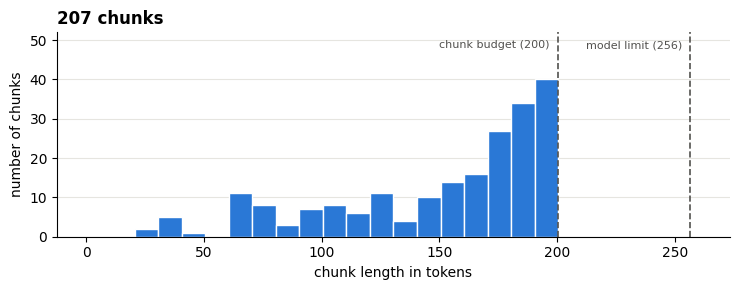

--- chunk 140 | p. 53 | 179 tokens
Spouses Working for the Same Employer: Eligible spouses who work for the same employer are limited to a combined total of 12 workweeks of leave in a 12-month period to share for the following FMLA-qualifying reasons: • The birth of a son or daughter and bonding with the newborn child, • The placement of a son or daughter with the employee for adoption or foster care, and bonding with the newly-placed child, and • The care of a parent with a serious health condition. Eligible spouses who work for the same employer are also limited to a combined total of 26 workweeks in a single 12-month period to care for a covered servicemember with a serious injury or illness if each spouse is a parent, spouse, son or daughter, or next of kin of the servicemember (commonly referred to as "military caregiver leave").

--- chunk 141 | p. 53, 54 | 176 tokens
Spouses Working for the Same Employer: This limitation also applies to a combination of military caregiver leave 

In [17]:
import matplotlib.pyplot as plt

FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# Histogram of chunk lengths with the chunk budget and the model limit
# Bin edges sit at x.5 so that a chunk of exactly 200 tokens falls in the bar that ends at 200
fig, ax = plt.subplots(figsize=(7.5, 3))
counts, _, _ = ax.hist(chunks["n_tokens"], bins=np.arange(0.5, 261, 10), color="#2a78d6", edgecolor="white")
ax.set_ylim(0, counts.max() * 1.3)                     # headroom for the labels
for x, label in [(CHUNK_TOKENS, "chunk budget (200)"), (MODEL_MAX_TOKENS, "model limit (256)")]:
    ax.axvline(x + 0.5, color="#52514e", linestyle="--", linewidth=1.2)
    ax.text(x - 3, counts.max() * 1.25, label, ha="right", va="top", fontsize=8, color="#52514e")
ax.set_xlabel("chunk length in tokens")
ax.set_ylabel("number of chunks")
ax.set_title(f"{len(chunks)} chunks", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e0")
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "chunk_lengths.png"), dpi=150)
plt.show()

# Two example chunks
for section in ["Spouses Working for the Same Employer", "Limitations on an Employee's Right to Return to Work"]:
    for _, c in chunks[chunks["section"] == section].head(2).iterrows():
        print(f"--- chunk {c.chunk_id} | p. {c.pages} | {c.n_tokens} tokens\n{c.text}\n")

## Step 4: Embeddings, bi-encoder and vector store

- **Bi-encoder:** `all-MiniLM-L6-v2` (6-layer BERT, 22.7M parameters) turns each chunk into one 384-dimensional vector: Transformer, then mean pooling, then normalisation to length 1.
- **Vector store:** the vectors go into a FAISS `IndexFlatIP`.
  - It is an exact search by inner product.
  - Because the vectors have length 1, the inner product equals the cosine similarity.
- **Retrieval:** a question is embedded the same way, and the 10 chunks with the highest similarity are returned (Pipeline 1, part a and b).

In [18]:
import faiss
from sentence_transformers import SentenceTransformer

bi_encoder = SentenceTransformer(BI_ENCODER_NAME, device="cpu")

# The model's own input limit must match what Step 3 assumed, and its tokenizer must count
# our chunks exactly like the tokenizer we used for chunking
assert bi_encoder.max_seq_length == MODEL_MAX_TOKENS
assert all(len(bi_encoder.tokenizer.tokenize(t)) == n for t, n in zip(chunks["text"], chunks["n_tokens"]))

n_params = sum(p.numel() for p in bi_encoder.parameters())
print(f"bi-encoder: {BI_ENCODER_NAME} | {n_params / 1e6:.1f}M parameters | max {bi_encoder.max_seq_length} tokens")
print(bi_encoder)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

bi-encoder: sentence-transformers/all-MiniLM-L6-v2 | 22.7M parameters | max 256 tokens
SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({'module_input_name': 'sentence_embedding', 'module_output_name': 'sentence_embedding'})
)


In [19]:
# Offline step: embed every chunk once. normalize_embeddings=True gives vectors of length 1,
# so inner product = cosine similarity.
start = time.perf_counter()
chunk_vecs = bi_encoder.encode(chunks["text"].tolist(), batch_size=32,
                               normalize_embeddings=True, show_progress_bar=False)
embed_seconds = time.perf_counter() - start

norms = np.linalg.norm(chunk_vecs, axis=1)
print(f"embedded {chunk_vecs.shape[0]} chunks -> shape {chunk_vecs.shape}, dtype {chunk_vecs.dtype}, "
      f"in {embed_seconds:.1f} s ({1000 * embed_seconds / len(chunks):.0f} ms per chunk)")
print(f"vector lengths: min {norms.min():.4f}, max {norms.max():.4f}")
print("first 8 numbers of chunk 0:", np.round(chunk_vecs[0, :8], 3))
assert np.allclose(norms, 1.0, atol=1e-4)

embedded 207 chunks -> shape (207, 384), dtype float32, in 4.7 s (22 ms per chunk)
vector lengths: min 1.0000, max 1.0000
first 8 numbers of chunk 0: [ 0.014  0.06  -0.094  0.049  0.036  0.063 -0.029 -0.002]


In [20]:
# Vector store: exact inner-product search over all chunk vectors
index = faiss.IndexFlatIP(chunk_vecs.shape[1])
index.add(chunk_vecs)
print(f"FAISS index: {index.ntotal} vectors of dimension {index.d} "
      f"(~{chunk_vecs.nbytes / 1e6:.2f} MB)")
assert index.ntotal == len(chunks)


def retrieve(query, k=10):
    """Pipeline 1, steps a-b: embed the query and return the top-k chunks by cosine similarity."""
    q_vec = bi_encoder.encode([query], normalize_embeddings=True)
    scores, ids = index.search(q_vec, k)                  # both have shape (1, k)
    result = chunks.iloc[ids[0]].copy()
    result.insert(0, "bi_rank", range(1, k + 1))
    result.insert(2, "bi_score", scores[0])
    return result.reset_index(drop=True)


FAISS index: 207 vectors of dimension 384 (~0.32 MB)


In [21]:
# Checks
# 1. FAISS scores are exactly the cosine similarities we can compute by hand
query = "Can spouses who work for the same employer each take 12 weeks of leave?"
top = retrieve(query)
q_vec = bi_encoder.encode([query], normalize_embeddings=True)[0]
manual = chunk_vecs[top["chunk_id"]] @ q_vec / (np.linalg.norm(chunk_vecs[top["chunk_id"]], axis=1) * np.linalg.norm(q_vec))
assert np.allclose(manual, top["bi_score"], atol=1e-5)

# 2. Scores are sorted from best to worst
assert (np.diff(top["bi_score"]) <= 1e-6).all()

# 3. A sentence copied from the document finds its own chunk at rank 1
sentence = "Eligible spouses who work for the same employer are limited to a combined total of 12 workweeks"
assert sentence in retrieve(sentence).iloc[0]["text"]

print("all checks passed")

all checks passed


In [22]:
# A first look at the baseline retriever on three realistic questions
questions = [
    "My wife and I work for the same company. Can each of us take 12 weeks of FMLA leave for our new baby?",
    "How many weeks of leave can I take to care for my son who was seriously injured in military service?",
    "Can my employer count my FMLA absences against me under a no-fault attendance policy?",
]
for question in questions:
    start = time.perf_counter()
    top10 = retrieve(question)
    ms = 1000 * (time.perf_counter() - start)
    print(f"\nQ: {question}   ({ms:.0f} ms)")
    for _, r in top10.iterrows():
        print(f"  #{r.bi_rank:<2} chunk {r.chunk_id:>3}  {r.bi_score:.3f}  p.{r.pages:<7} {r.section[:60]}")


Q: My wife and I work for the same company. Can each of us take 12 weeks of FMLA leave for our new baby?   (14 ms)
  #1  chunk   0  0.720  p.6       Introduction
  #2  chunk  50  0.708  p.23      Circumstances that Qualify for FMLA Leave
  #3  chunk  52  0.703  p.23      Circumstances that Qualify for FMLA Leave
  #4  chunk 140  0.686  p.53      Spouses Working for the Same Employer
  #5  chunk 141  0.685  p.53, 54  Spouses Working for the Same Employer
  #6  chunk 144  0.681  p.54      Spouses Working for the Same Employer
  #7  chunk  37  0.663  p.18      50 Employees within 75 Miles of the Employee's Worksite
  #8  chunk 142  0.655  p.54      Spouses Working for the Same Employer
  #9  chunk  51  0.650  p.23      Circumstances that Qualify for FMLA Leave
  #10 chunk   1  0.634  p.6       Introduction

Q: How many weeks of leave can I take to care for my son who was seriously injured in military service?   (13 ms)
  #1  chunk 104  0.713  p.41      Military Caregiver Leave
  #2  chun

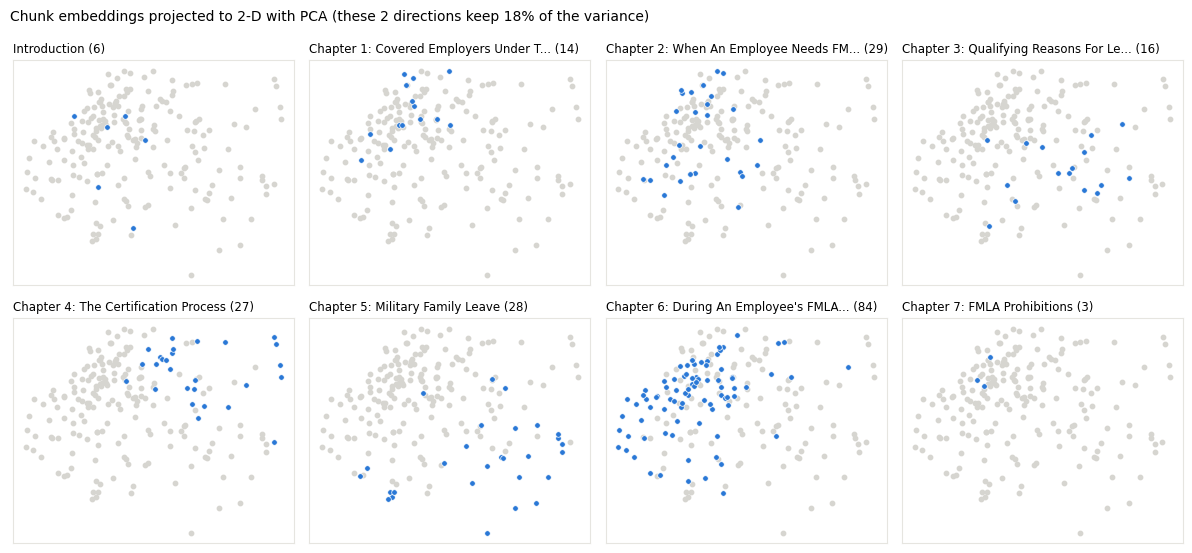

In [23]:
# 2-D map of the 207 chunk vectors: PCA projects 384 dimensions onto the 2 directions with the
# most variance. One small panel per chapter (that chapter in blue, all other chunks in grey).
centered = chunk_vecs - chunk_vecs.mean(axis=0)
_, sing_vals, components = np.linalg.svd(centered, full_matrices=False)
xy = centered @ components[:2].T
explained = sing_vals[:2] ** 2 / (sing_vals ** 2).sum()

chapters = list(dict.fromkeys(chunks["chapter"]))
fig, axes = plt.subplots(2, 4, figsize=(12, 5.6), sharex=True, sharey=True)
for ax, chapter in zip(axes.flat, chapters):
    mask = (chunks["chapter"] == chapter).to_numpy()
    ax.scatter(xy[~mask, 0], xy[~mask, 1], s=10, color="#d6d5d0")
    ax.scatter(xy[mask, 0], xy[mask, 1], s=16, color="#2a78d6", edgecolor="white", linewidth=0.5)
    title = chapter if len(chapter) <= 38 else chapter[:36] + "..."
    ax.set_title(f"{title} ({mask.sum()})", fontsize=8.5, loc="left")
    ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_color("#e6e5e0")
fig.suptitle(f"Chunk embeddings projected to 2-D with PCA "
             f"(these 2 directions keep {explained.sum():.0%} of the variance)", x=0.01, ha="left", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "embedding_map.png"), dpi=150)
plt.show()

## Step 5: Grounded generation (Pipeline 1)

Pipeline 1 = bi-encoder top 10, then **ranks 1-3 unchanged**, then Gemini, giving **Answer 1**.

- **One prompt template** (`build_prompt`) is used by both pipelines; only the chunks differ.
  - The system instruction asks Gemini to use only the context, to say a fixed sentence when the answer is missing, to include conditions and exceptions, and to cite chunks like `[C140]`.
- **Settings:** `temperature=0` and `thinking_level="low"` (hidden reasoning kept low, so the answer depends on the retrieved context).
- **Answers are cached** in `results/llm_cache.json`.
  - Re-running the notebook shows exactly the answers analysed in the report and does not use up the free-tier quota.
  - Latency is measured separately in Step 8 with uncached calls.

In [24]:
import hashlib

SYSTEM_INSTRUCTION = """You answer questions about the U.S. Department of Labor's "Employer's Guide to the Family and Medical Leave Act".
Rules:
1. Use ONLY the context chunks below. Do not use outside knowledge.
2. If the context does not contain the answer, say exactly: "The provided context does not contain the answer."
3. Include any conditions, limits or exceptions that the context states.
4. Cite the chunks you used, like [C140].
5. Answer in at most 4 sentences."""
NOT_FOUND = "The provided context does not contain the answer."

TEMPERATURE = 0
THINKING_LEVEL = "low"
GEN_CONFIG = types.GenerateContentConfig(
    system_instruction=SYSTEM_INSTRUCTION,
    temperature=TEMPERATURE,
    thinking_config=types.ThinkingConfig(thinking_level=THINKING_LEVEL),
)


def build_prompt(question, context_chunks):
    """The ONE prompt template used by both pipelines: labelled chunks in rank order, then the question."""
    blocks = [f"[C{c.chunk_id}] (page {c.pages})\n{c.text}" for c in context_chunks.itertuples()]
    return "Context:\n" + "\n\n".join(blocks) + f"\n\nQuestion: {question}\nAnswer:"

In [25]:
CACHE_PATH = os.path.join(RESULTS_DIR, "llm_cache.json")
llm_cache = json.load(open(CACHE_PATH)) if os.path.exists(CACHE_PATH) else {}
api_calls = 0      # counts real requests to Gemini (cache hits do not count)
MIN_SECONDS_BETWEEN_CALLS = 4.5   # free tier allows 15 requests per minute
last_call_time = 0.0


def cache_key(prompt):
    """Everything that determines the answer goes into the key."""
    parts = [GEMINI_MODEL, SYSTEM_INSTRUCTION, prompt, str(TEMPERATURE), THINKING_LEVEL]
    return hashlib.sha256("\n||\n".join(parts).encode()).hexdigest()


def generate(prompt, use_cache=True):
    """Ask Gemini for an answer, reusing the cached answer for an identical request."""
    global api_calls, last_call_time
    key = cache_key(prompt)
    if use_cache and key in llm_cache:
        return llm_cache[key]["answer"]

    # stay under the free-tier limit of 15 requests per minute
    wait = MIN_SECONDS_BETWEEN_CALLS - (time.perf_counter() - last_call_time)
    if wait > 0:
        time.sleep(wait)

    start = time.perf_counter()
    response = client.models.generate_content(model=GEMINI_MODEL, contents=prompt, config=GEN_CONFIG)
    last_call_time = time.perf_counter()
    api_calls += 1
    usage = response.usage_metadata
    llm_cache[key] = {
        "answer": (response.text or "").strip(),
        "seconds": round(time.perf_counter() - start, 2),
        "prompt_tokens": usage.prompt_token_count,
        "answer_tokens": usage.candidates_token_count,
        "thinking_tokens": usage.thoughts_token_count,
    }
    with open(CACHE_PATH, "w") as f:
        json.dump(llm_cache, f, indent=2)
    return llm_cache[key]["answer"]


def cited_ids(answer):
    """Chunk ids cited in an answer, e.g. '[C140]' or '[C140, C141]' -> [140, 141]."""
    return [int(n) for group in re.findall(r"\[([^\]]*)\]", answer) for n in re.findall(r"C(\d+)", group)]


print(f"{len(llm_cache)} cached answers loaded from {CACHE_PATH}")

41 cached answers loaded from results/llm_cache.json


In [26]:
def pipeline_baseline(question, k=10, n_context=3):
    """Pipeline 1: bi-encoder top-k, the first n_context chunks unchanged, then Gemini -> Answer 1."""
    top_k = retrieve(question, k=k)
    context = top_k.head(n_context)
    prompt = build_prompt(question, context)
    answer = generate(prompt)
    return {"question": question, "answer": answer, "context_ids": context["chunk_id"].tolist(),
            "prompt": prompt, "top_k": top_k}


def print_result(result, label="Answer 1"):
    print(f"Q: {result['question']}")
    print(f"context chunks: {result['context_ids']}")
    print(f"{label}: {result['answer']}")
    print(f"cited: {cited_ids(result['answer'])}\n")

In [27]:
# Checks
# 1. The prompt contains exactly the top-3 chunks, in rank order
r = pipeline_baseline(questions[0])
labels = [int(x) for x in re.findall(r"^\[C(\d+)\] \(page", r["prompt"], flags=re.M)]
assert labels == r["top_k"]["chunk_id"].head(3).tolist(), labels

# 2. Grounding: a question the guide does not cover must give the fixed "not found" sentence
off_topic = pipeline_baseline("What is the minimum wage in California?")
print("off-topic question ->", off_topic["answer"])
assert NOT_FOUND in off_topic["answer"]

# 3. Cache: asking the same question again returns identical text without a new API request
calls_before = api_calls
again = pipeline_baseline(questions[0])
assert again["answer"] == r["answer"] and api_calls == calls_before

print("all checks passed")

off-topic question -> The provided context does not contain the answer.
all checks passed


In [28]:
# Answer 1 for the three questions from Step 4
baseline_results = [pipeline_baseline(q) for q in questions]
for res in baseline_results:
    print_result(res, "Answer 1")
    # every citation must point to a chunk that was really in the prompt
    assert set(cited_ids(res["answer"])) <= set(res["context_ids"]), "cites a chunk it was not given"

print(f"Gemini requests made in this run: {api_calls} (the rest came from the cache)")

Q: My wife and I work for the same company. Can each of us take 12 weeks of FMLA leave for our new baby?
context chunks: [0, 50, 52]
Answer 1: The provided context does not contain the answer.
cited: []

Q: How many weeks of leave can I take to care for my son who was seriously injured in military service?
context chunks: [104, 98, 1]
Answer 1: You can take up to a total of 26 workweeks of unpaid leave during a "single 12-month period" to care for your son if he is a covered servicemember with a serious injury or illness [C104]. To be eligible, you must be the spouse, son, daughter, parent, or next of kin of the servicemember [C104]. However, you are limited to a combined total of 26 workweeks of leave for any FMLA-qualifying reasons during this single 12-month period [C1].
cited: [104, 104, 1]

Q: Can my employer count my FMLA absences against me under a no-fault attendance policy?
context chunks: [81, 2, 152]
Answer 1: The provided context does not contain the answer.
cited: []

Gemi

## Step 6: Cross-encoder re-ranking (Pipeline 2)

Pipeline 2 starts from the **same top 10** as Pipeline 1.

- **Score:** each (question, chunk) pair is scored by the cross-encoder `cross-encoder/ms-marco-MiniLM-L-6-v2`.
  - It reads `[CLS] question [SEP] chunk [SEP]` as one input, so question and chunk tokens attend to each other in every layer.
  - It outputs one relevance score (a logit).
- **Re-sort:** the candidates are ordered by that score.
- **Generate:** the **new top 3** go into the **same prompt** with the **same LLM**, giving **Answer 2**.

The only difference between the pipelines is the order of the candidates.

In [29]:
from sentence_transformers import CrossEncoder

CROSS_ENCODER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"
cross_encoder = CrossEncoder(CROSS_ENCODER_NAME, device="cpu")

ce_config = cross_encoder.model.config
n_params = sum(p.numel() for p in cross_encoder.model.parameters())
print(f"cross-encoder: {CROSS_ENCODER_NAME} | {ce_config.num_hidden_layers} layers | "
      f"{n_params / 1e6:.1f}M parameters | max {cross_encoder.max_seq_length} tokens | {ce_config.num_labels} output score")

# What the model actually reads: question and chunk as ONE sequence
example = cross_encoder.tokenizer("Can spouses share leave?", "Spouses share a combined total of 12 workweeks.")
print(cross_encoder.tokenizer.convert_ids_to_tokens(example["input_ids"]))
print("segment ids:", example["token_type_ids"])

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

cross-encoder: cross-encoder/ms-marco-MiniLM-L-6-v2 | 6 layers | 22.7M parameters | max 512 tokens | 1 output score
['[CLS]', 'can', 'spouse', '##s', 'share', 'leave', '?', '[SEP]', 'spouse', '##s', 'share', 'a', 'combined', 'total', 'of', '12', 'work', '##week', '##s', '.', '[SEP]']
segment ids: [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [30]:
def rerank(question, candidates):
    """Pipeline 2, steps b-c: score every (question, chunk) pair and sort by the cross-encoder score."""
    pairs = [(question, text) for text in candidates["text"]]
    scored = candidates.copy()
    scored["ce_score"] = cross_encoder.predict(pairs, show_progress_bar=False)
    scored = scored.sort_values("ce_score", ascending=False).reset_index(drop=True)
    scored.insert(1, "ce_rank", range(1, len(scored) + 1))
    return scored


def pipeline_rerank(question, k=10, n_context=3):
    """Pipeline 2: same bi-encoder top-k, re-ranked by the cross-encoder, new top n_context -> Answer 2."""
    top_k = retrieve(question, k=k)                   # identical candidates to Pipeline 1
    reranked = rerank(question, top_k)
    context = reranked.head(n_context)
    prompt = build_prompt(question, context)          # identical prompt template
    answer = generate(prompt)                         # identical model and settings
    return {"question": question, "answer": answer, "context_ids": context["chunk_id"].tolist(),
            "prompt": prompt, "reranked": reranked}


def rank_shift_table(reranked, n_context=3):
    """One row per candidate: bi-encoder rank -> cross-encoder rank, and which answer saw it."""
    table = reranked[["chunk_id", "bi_rank", "ce_rank", "bi_score", "ce_score", "section", "pages"]].copy()
    table = table.sort_values("bi_rank").reset_index(drop=True)
    table["shift"] = table["bi_rank"] - table["ce_rank"]          # positive = moved up
    in1, in2 = table["bi_rank"] <= n_context, table["ce_rank"] <= n_context
    table["in_context"] = np.select([in1 & in2, in1, in2], ["both", "Answer 1 only", "Answer 2 only"], "-")
    table["section"] = table["section"].str.slice(0, 45)
    return table


def compare(question):
    """Run both pipelines on one question and print the rank shifts and both answers."""
    base, rr = pipeline_baseline(question), pipeline_rerank(question)
    table = rank_shift_table(rr["reranked"])
    print(f"Q: {question}\n")
    print(table.to_string(index=False, formatters={"bi_score": "{:.3f}".format, "ce_score": "{:+.2f}".format}))
    for _, row in table[table["in_context"].isin(["Answer 1 only", "Answer 2 only"])].iterrows():
        print(f"  chunk {row.chunk_id}: rank #{row.bi_rank} -> #{row.ce_rank}  ({row.in_context})")
    print(f"\nAnswer 1 (chunks {base['context_ids']}): {base['answer']}")
    print(f"Answer 2 (chunks {rr['context_ids']}): {rr['answer']}\n")
    return {"question": question, "answer_1": base["answer"], "answer_2": rr["answer"],
            "context_1": base["context_ids"], "context_2": rr["context_ids"], "table": table}

In [31]:
# Checks
q = questions[0]
top10 = retrieve(q)
reranked = rerank(q, top10)

# 1. Re-ranking only changes the order: the same 10 chunk ids
assert sorted(reranked["chunk_id"]) == sorted(top10["chunk_id"])
# 2. Sorted from the highest to the lowest cross-encoder score
assert (np.diff(reranked["ce_score"]) <= 0).all()
# 3. Deterministic: scoring the same pairs again gives the same numbers
assert np.allclose(rerank(q, top10).set_index("chunk_id")["ce_score"],
                   reranked.set_index("chunk_id")["ce_score"])
# 4. Both pipelines build their prompt with build_prompt from the same kind of input
assert pipeline_rerank(q)["prompt"] == build_prompt(q, reranked.head(3))

print("all checks passed")

all checks passed


In [32]:
# Pipeline 1 vs Pipeline 2 on the three questions from Step 4
comparisons = [compare(q) for q in questions]
print(f"Gemini requests made so far in this run: {api_calls}")

Q: My wife and I work for the same company. Can each of us take 12 weeks of FMLA leave for our new baby?

 chunk_id  bi_rank  ce_rank bi_score ce_score                                       section  pages  shift    in_context
        0        1        5    0.720    +2.20                                  Introduction      6     -4 Answer 1 only
       50        2        3    0.708    +2.96     Circumstances that Qualify for FMLA Leave     23     -1          both
       52        3        7    0.703    +1.36     Circumstances that Qualify for FMLA Leave     23     -4 Answer 1 only
      140        4        1    0.686    +5.09         Spouses Working for the Same Employer     53      3 Answer 2 only
      141        5        6    0.685    +2.15         Spouses Working for the Same Employer 53, 54     -1             -
      144        6        4    0.681    +2.50         Spouses Working for the Same Employer     54      2             -
       37        7        9    0.663    -0.10 50 Emplo

Q: How many weeks of leave can I take to care for my son who was seriously injured in military service?

 chunk_id  bi_rank  ce_rank bi_score ce_score                                   section  pages  shift    in_context
      104        1        1    0.713    +6.85                  Military Caregiver Leave     41      0          both
       98        2        9    0.652    -0.59            Qualifying Exigency Categories 38, 39     -7 Answer 1 only
        1        3        3    0.632    +4.12                              Introduction      6      0          both
      112        4        5    0.575    +1.92                A "Single 12-Month Period"     44     -1             -
       51        5        2    0.562    +5.08 Circumstances that Qualify for FMLA Leave     23      3 Answer 2 only
      140        6        4    0.560    +3.18     Spouses Working for the Same Employer     53      2             -
       50        7        6    0.558    +0.28 Circumstances that Qualify for FMLA L

Q: Can my employer count my FMLA absences against me under a no-fault attendance policy?

 chunk_id  bi_rank  ce_rank bi_score ce_score                                       section  pages  shift    in_context
       81        1        4    0.680    +0.38 Incomplete or Insufficient Medical Certificat     33     -3 Answer 1 only
        2        2        9    0.660    -3.16                                  Introduction      6     -7 Answer 1 only
      152        3        2    0.658    +2.84 Increments of FMLA Leave for Intermittent or      56      1          both
      158        4        1    0.650    +4.19                    FMLA and Other Paid Leaves     58      3 Answer 2 only
      175        5        8    0.637    -2.93      When an Employee Fails to Return to Work     63     -3             -
      191        6        7    0.634    -2.38                            Content of Records     67     -1             -
       77        7        6    0.624    -1.90 Additional Information f

## Step 7: Failure-mode stress testing

- **Test set:** 21 questions, written **before** running anything (no cherry-picking). Each question has a failure-mode type:
  - **K** = keyword trap / distractor
  - **E** = exception located elsewhere
  - **N** = negation / constraint
  - **C** = control
- **Gold labels:** each question has **evidence phrases**, exact quotes from the guide. The gold chunks are all chunks that contain one.
- **Ranking:** for every question we record where the gold chunk lands in Pipeline 1 (bi-encoder rank over all 207 chunks) and in Pipeline 2 (cross-encoder rank in the top 10). From those ranks we compute Hit@3, Recall@10, MRR@10 and an outcome per question.
- **Answers:** Answer 1 and Answer 2 are generated for all 21 questions, with automatic signals (abstained? gold chunk in the context? gold chunk cited?). Judging correctness is left to the reader of `results/answers.csv`.

In [33]:
TEST_SET = [
    {"id": "Q01", "type": "N", "question": "My wife and I work for the same company. Can each of us take 12 weeks of FMLA leave for our new baby?",
     "evidence": ["are limited to a combined total of 12 workweeks of leave in a 12-month period to share"]},
    {"id": "Q02", "type": "E", "question": "My wife and I work for the same company and share the 12-week limit for our baby. Does that shared limit also apply to her own recovery after giving birth?",
     "evidence": ["This limitation does not apply to leave"]},
    {"id": "Q03", "type": "N", "question": "My girlfriend and I are not married but work for the same employer. Do we have to share 12 weeks of leave for our child?",
     "evidence": ["who are not legally married"]},
    {"id": "Q04", "type": "N", "question": "Can my employer count my FMLA absences against me under a no-fault attendance policy?",
     "evidence": ["no fault"]},
    {"id": "Q05", "type": "N", "question": "Is an employer allowed to move employees to another site to keep a worksite under 50 employees so nobody qualifies for FMLA?",
     "evidence": ["keeping a worksite below"]},
    {"id": "Q06", "type": "E", "question": "Does my employer always have to give me my job back when I return from FMLA leave?",
     "evidence": ["deny restoration to a"]},
    {"id": "Q07", "type": "K,N", "question": "Can my employer require a second medical opinion on my fitness-for-duty certification before I return to work?",
     "evidence": ["may not require second or third opinions"]},
    {"id": "Q08", "type": "K,N", "question": "My employer asked for a second opinion on my qualifying exigency leave certification. Is that allowed?",
     "evidence": ["not permitted to require second and third opinions"]},
    {"id": "Q09", "type": "N", "question": "Can my direct supervisor call my doctor to clarify my medical certification?",
     "evidence": ["direct supervisor"]},
    {"id": "Q10", "type": "N", "question": "Does my vacation time count toward the 1,250 hours of service?",
     "evidence": ["is not counted towards the 1,250 hours"]},
    {"id": "Q11", "type": "E,K", "question": "I am a flight attendant. How many hours must I have worked in the last year to qualify for FMLA leave?",
     "evidence": ["worked or been paid for not less than 504 hours"]},
    {"id": "Q12", "type": "K", "question": "Do the 12 months I worked for my employer have to be in a row?",
     "evidence": ["The 12 months of employment do not have to be consecutive"]},
    {"id": "Q13", "type": "N", "question": "Can I take FMLA leave to care for my mother-in-law?",
     "evidence": ["parents-in-law"]},
    {"id": "Q14", "type": "K", "question": "My grandmother raised me after my parents died. Can I take FMLA leave to care for her?",
     "evidence": ["in loco parentis"]},
    {"id": "Q15", "type": "E", "question": "Can my employer cancel my health insurance if I stop paying my share of the premium while on FMLA leave?",
     "evidence": ["30 days late"]},
    {"id": "Q16", "type": "E", "question": "If I decide not to come back after FMLA leave, can my employer make me pay back the health insurance premiums?",
     "evidence": ["The employer may recover from an employee its share of health plan premiums"]},
    {"id": "Q17", "type": "C", "question": "Can my employer make me use my paid vacation days during my FMLA leave?",
     "evidence": ["or an employer may require the employee, to substitute accrued paid leave"]},
    {"id": "Q18", "type": "C", "question": "How far in advance do I need to tell my employer about a planned surgery?",
     "evidence": ["at least 30 days advance notice"]},
    {"id": "Q19", "type": "E", "question": "Is a teacher's leave near the end of the school semester handled differently?",
     "evidence": ["near the end of an academic term"]},
    {"id": "Q20", "type": "K,N", "question": "I work from home. Is my house counted as my worksite for the 50-employees-within-75-miles rule?",
     "evidence": ["personal residence is not a worksite"]},
    {"id": "Q21", "type": "C", "question": "How many weeks of leave can I take to care for my son who was seriously injured in military service?",
     "evidence": ["26 workweeks of leave during a single 12-month period to care for a covered servicemember", "a total of 26 workweeks of"]},
]
print(len(TEST_SET), "test questions")

21 test questions


In [34]:
def gold_ids(item):
    """All chunks that contain one of the item's evidence phrases (case-insensitive)."""
    phrases = [e.lower() for e in item["evidence"]]
    mask = chunks["text"].str.lower().apply(lambda t: any(p in t for p in phrases))
    ids = set(chunks.loc[mask, "chunk_id"])
    assert ids, f"{item['id']}: evidence phrase not found in any chunk"
    return ids


def outcome(bi_rank, ce_rank, n_context=3, k=10):
    if bi_rank > k:
        return "both miss (recall)"
    hit_1, hit_2 = bi_rank <= n_context, ce_rank <= n_context
    if hit_1 and hit_2:
        return "both hit"
    if hit_2:
        return "fixed by re-ranking"
    if hit_1:
        return "broken by re-ranking"
    return "both miss (ranking)"


def evaluate(item, k=10):
    """Gold-chunk rank in Pipeline 1 (over ALL chunks) and in Pipeline 2 (inside the top k)."""
    gold = gold_ids(item)
    full = retrieve(item["question"], k=len(chunks))        # every chunk, ranked by the bi-encoder
    bi_rank = int(full.loc[full["chunk_id"].isin(gold), "bi_rank"].min())
    reranked = rerank(item["question"], full.head(k))       # identical to Pipeline 2's re-ranking
    hits = reranked.loc[reranked["chunk_id"].isin(gold), "ce_rank"]
    ce_rank = int(hits.min()) if len(hits) else None
    best_gold = int(full.loc[full["chunk_id"].isin(gold)].iloc[0]["chunk_id"])
    return {"id": item["id"], "type": item["type"], "gold": sorted(gold), "best_gold": best_gold,
            "bi_rank": bi_rank, "ce_rank": ce_rank,
            "outcome": outcome(bi_rank, ce_rank if ce_rank else k + 1),
            "top3_p1": full["chunk_id"].head(3).tolist(), "top3_p2": reranked["chunk_id"].head(3).tolist(),
            "question": item["question"]}


eval_df = pd.DataFrame([evaluate(item) for item in TEST_SET])
eval_df["ce_rank"] = eval_df["ce_rank"].astype("Int64")      # keeps "not in top 10" as <NA>
eval_df.to_csv(os.path.join(RESULTS_DIR, "rank_shifts.csv"), index=False)

view = eval_df[["id", "type", "gold", "bi_rank", "ce_rank", "outcome"]].copy()
view["shift"] = [f"#{b} -> #{c}" if pd.notna(c) else f"#{b} -> not in top 10" for b, c in zip(view.bi_rank, view.ce_rank)]
print(view.to_string(index=False))

 id type         gold  bi_rank  ce_rank             outcome                shift
Q01    N        [140]        4        1 fixed by re-ranking             #4 -> #1
Q02    E        [141]        1        3            both hit             #1 -> #3
Q03    N        [141]        2        3            both hit             #2 -> #3
Q04    N        [205]       15     <NA>  both miss (recall) #15 -> not in top 10
Q05    N        [204]        7        2 fixed by re-ranking             #7 -> #2
Q06    E        [186]       30     <NA>  both miss (recall) #30 -> not in top 10
Q07  K,N        [128]        1        1            both hit             #1 -> #1
Q08  K,N   [102, 103]        1        1            both hit             #1 -> #1
Q09    N         [83]        1        1            both hit             #1 -> #1
Q10    N         [31]        1        1            both hit             #1 -> #1
Q11  E,K         [40]       10        3 fixed by re-ranking            #10 -> #3
Q12    K         [29]       

In [35]:
# Summary metrics over the 21 questions
k, n = 10, 3
ce_ranks = eval_df["ce_rank"].fillna(k + 1).astype(int)
summary = pd.DataFrame({
    "Pipeline 1 (bi-encoder)": {
        "Hit@3": (eval_df["bi_rank"] <= n).mean(),
        "Recall@10": (eval_df["bi_rank"] <= k).mean(),
        "MRR@10": np.where(eval_df["bi_rank"] <= k, 1 / eval_df["bi_rank"], 0).mean()},
    "Pipeline 2 (+ cross-encoder)": {
        "Hit@3": (ce_ranks <= n).mean(),
        "Recall@10": (eval_df["bi_rank"] <= k).mean(),
        "MRR@10": np.where(ce_ranks <= k, 1 / ce_ranks, 0).mean()},
}).round(3)
print(summary.to_string(), "\n")
print(eval_df["outcome"].value_counts().to_string())
summary.to_csv(os.path.join(RESULTS_DIR, "retrieval_metrics.csv"))

           Pipeline 1 (bi-encoder)  Pipeline 2 (+ cross-encoder)
Hit@3                        0.571                         0.857
Recall@10                    0.857                         0.857
MRR@10                       0.574                         0.683 

outcome
both hit               12
fixed by re-ranking     6
both miss (recall)      3


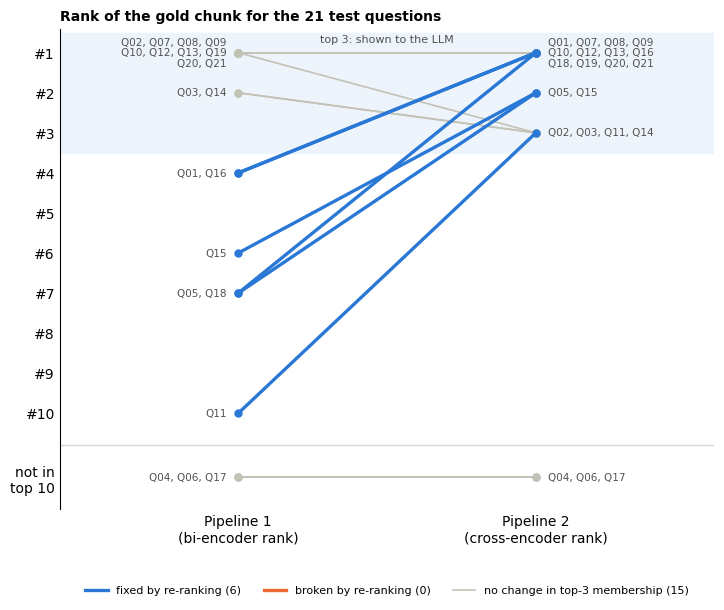

In [36]:
# Slope chart: gold-chunk rank in Pipeline 1 (left) vs Pipeline 2 (right).
# Questions whose gold chunk is not in the top 10 are drawn in a band below rank 10.
COLORS = {"fixed by re-ranking": "#2a78d6", "broken by re-ranking": "#eb6834"}
OUT_Y = k + 1.6                                            # position of the "not in top 10" band

fig, ax = plt.subplots(figsize=(7.5, 6.2))
ax.axhspan(0.5, n + 0.5, color="#eef4fc", zorder=0)        # the top-3 zone the LLM sees
ax.text(0.5, 0.75, "top 3: shown to the LLM", ha="center", fontsize=8, color="#52514e")
ax.axhline(k + 0.8, color="#d6d5d0", linewidth=1)

left_labels, right_labels = {}, {}
for row in eval_df.itertuples():
    y1 = row.bi_rank if row.bi_rank <= k else OUT_Y
    y2 = row.ce_rank if pd.notna(row.ce_rank) else OUT_Y
    color = COLORS.get(row.outcome, "#c3c2b7")
    width = 2.4 if row.outcome in COLORS else 1.2
    ax.plot([0, 1], [y1, y2], color=color, linewidth=width, marker="o", markersize=5, zorder=3 if row.outcome in COLORS else 2)
    left_labels.setdefault(y1, []).append(row.id)
    right_labels.setdefault(y2, []).append(row.id)

def id_lines(ids, per_line=4):
    return "\n".join(", ".join(ids[i:i + per_line]) for i in range(0, len(ids), per_line))

for y, ids in left_labels.items():
    ax.text(-0.04, y, id_lines(ids), ha="right", va="center", fontsize=7.5, color="#52514e", linespacing=1.1)
for y, ids in right_labels.items():
    ax.text(1.04, y, id_lines(ids), ha="left", va="center", fontsize=7.5, color="#52514e", linespacing=1.1)

ax.set_ylim(OUT_Y + 0.8, 0.4)
ax.set_xlim(-0.6, 1.6)
ax.set_yticks(list(range(1, k + 1)) + [OUT_Y])
ax.set_yticklabels([f"#{i}" for i in range(1, k + 1)] + ["not in\ntop 10"])
ax.set_xticks([0, 1])
ax.set_xticklabels(["Pipeline 1\n(bi-encoder rank)", "Pipeline 2\n(cross-encoder rank)"])
for side in ("top", "right", "bottom"):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
counts = eval_df["outcome"].value_counts()
handles = [plt.Line2D([], [], color=c, linewidth=2.4, label=f"{l} ({counts.get(l, 0)})") for l, c in COLORS.items()]
n_other = len(eval_df) - sum(counts.get(l, 0) for l in COLORS)
handles.append(plt.Line2D([], [], color="#c3c2b7", linewidth=1.2, label=f"no change in top-3 membership ({n_other})"))
ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False, fontsize=8)
ax.set_title("Rank of the gold chunk for the 21 test questions", loc="left", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "rank_shifts.png"), dpi=150, bbox_inches="tight")
plt.show()

In [37]:
# Answer 1 vs Answer 2 for all 21 questions (cached answers cost nothing; new ones are throttled)
def answer_signals(answer, context_ids, gold):
    return {"abstained": NOT_FOUND in answer,
            "gold_in_context": bool(set(context_ids) & gold),
            "cites_gold": bool(set(cited_ids(answer)) & gold)}


rows = []
for item, ev in zip(TEST_SET, eval_df.itertuples()):
    gold = set(ev.gold)
    p1, p2 = pipeline_baseline(item["question"]), pipeline_rerank(item["question"])
    s1, s2 = answer_signals(p1["answer"], p1["context_ids"], gold), answer_signals(p2["answer"], p2["context_ids"], gold)
    rows.append({"id": item["id"], "type": item["type"], "outcome": ev.outcome, "question": item["question"],
                 "evidence": " | ".join(item["evidence"]), "gold": ev.gold,
                 "context_1": p1["context_ids"], "answer_1": p1["answer"], **{f"{k}_1": v for k, v in s1.items()},
                 "context_2": p2["context_ids"], "answer_2": p2["answer"], **{f"{k}_2": v for k, v in s2.items()},
                 "same_prompt": p1["prompt"] == p2["prompt"]})

answers_df = pd.DataFrame(rows)
answers_df.to_csv(os.path.join(RESULTS_DIR, "answers.csv"), index=False)
print(f"Gemini requests made so far in this run: {api_calls}\n")
print(answers_df[["id", "outcome", "gold_in_context_1", "abstained_1", "cites_gold_1",
                  "gold_in_context_2", "abstained_2", "cites_gold_2", "same_prompt"]].to_string(index=False))

Gemini requests made so far in this run: 0

 id             outcome  gold_in_context_1  abstained_1  cites_gold_1  gold_in_context_2  abstained_2  cites_gold_2  same_prompt
Q01 fixed by re-ranking              False         True         False               True        False          True        False
Q02            both hit               True        False          True               True        False          True        False
Q03            both hit               True        False          True               True        False          True        False
Q04  both miss (recall)              False         True         False              False         True         False        False
Q05 fixed by re-ranking              False         True         False               True        False          True        False
Q06  both miss (recall)              False         True         False              False        False         False        False
Q07            both hit               True        Fal

In [38]:
# Full Answer 1 vs Answer 2 for every question where the two pipelines saw different chunks
for row in answers_df[~answers_df["same_prompt"]].itertuples():
    ev = eval_df.set_index("id").loc[row.id]
    shift = f"#{ev.bi_rank} -> #{ev.ce_rank}" if pd.notna(ev.ce_rank) else f"#{ev.bi_rank} -> not in top 10"
    print(f"{row.id} [{row.type}] {row.outcome} | gold {row.gold}: {shift}")
    print(f"Q: {row.question}")
    print(f"evidence: \"{row.evidence}\"")
    print(f"Answer 1 (chunks {row.context_1}): {row.answer_1}")
    print(f"Answer 2 (chunks {row.context_2}): {row.answer_2}\n")

Q01 [N] fixed by re-ranking | gold [140]: #4 -> #1
Q: My wife and I work for the same company. Can each of us take 12 weeks of FMLA leave for our new baby?
evidence: "are limited to a combined total of 12 workweeks of leave in a 12-month period to share"
Answer 1 (chunks [0, 50, 52]): The provided context does not contain the answer.
Answer 2 (chunks [140, 142, 50]): No, eligible spouses who work for the same employer are limited to a combined total of 12 workweeks of leave in a 12-month period to share for the birth and bonding with a newborn child [C140]. Therefore, you cannot each take 12 separate weeks for this reason, as the 12-workweek limit must be shared between you [C140].

Q02 [E] both hit | gold [141]: #1 -> #3
Q: My wife and I work for the same company and share the 12-week limit for our baby. Does that shared limit also apply to her own recovery after giving birth?
evidence: "This limitation does not apply to leave"
Answer 1 (chunks [141, 140, 142]): No, the shared 12-week

In [39]:
# Label audit (done after reading the answers).
# Q14's pre-registered evidence phrase "in loco parentis" turned out to be too broad: chunk 55 uses the term
# only in the definition of "son or daughter", while the answer to Q14 (someone who raised you counts as a
# parent) is in chunk 54. The metrics above keep the pre-registered label; this shows what a stricter
# phrase changes.
q14 = next(item for item in TEST_SET if item["id"] == "Q14")
strict = {**q14, "evidence": ["any other individual who stood in loco parentis to the employee"]}
before, after = evaluate(q14), evaluate(strict)
for label, res in [("pre-registered", before), ("strict", after)]:
    print(f"{label:15} gold {res['gold']}: bi rank #{res['bi_rank']} -> CE rank #{res['ce_rank']}  ({res['outcome']})")

pre-registered  gold [54, 55, 57]: bi rank #2 -> CE rank #3  (both hit)
strict          gold [54]: bi rank #5 -> CE rank #3  (fixed by re-ranking)


## Step 8: Latency profiling

Each pipeline is split into stages and every stage is timed with `time.perf_counter()`:

1. query embedding (bi-encoder)
2. FAISS search for the top 10
3. cross-encoder re-ranking of 10 pairs (Pipeline 2 only)
4. Gemini generation

How the measurements are made:
- **Local stages (1-3):** after a warm-up, they are timed on all 21 test questions, 3 rounds each.
- **Generation (4):** timed with real, **uncached** Gemini calls; the cached answers from Step 7 are not touched. These timings are saved to `results/latency_llm.json` and only re-measured if that file is missing, so re-running the notebook does not use quota.
- **Summary:** mean, median and 95th percentile for each stage.
- **Offline cost:** embedding the 207 chunks is a one-time cost and is reported separately.

In [40]:
def time_stages(question, k=10):
    """Time the local stages of both pipelines for one question (milliseconds)."""
    t0 = time.perf_counter()
    q_vec = bi_encoder.encode([question], normalize_embeddings=True)          # 1. query embedding
    t1 = time.perf_counter()
    _, ids = index.search(q_vec, k)                                           # 2. vector search
    t2 = time.perf_counter()
    pairs = [(question, text) for text in chunks["text"].iloc[ids[0]]]
    cross_encoder.predict(pairs, show_progress_bar=False)                     # 3. re-ranking (Pipeline 2)
    t3 = time.perf_counter()
    return {"embed_ms": 1000 * (t1 - t0), "search_ms": 1000 * (t2 - t1), "rerank_ms": 1000 * (t3 - t2)}


test_questions = [item["question"] for item in TEST_SET]
for q in test_questions[:5]:                       # warm-up: not recorded
    time_stages(q)

ROUNDS = 3
stage_times = pd.DataFrame([{"question": q, **time_stages(q)} for _ in range(ROUNDS) for q in test_questions])
stage_times["retrieval_p1_ms"] = stage_times["embed_ms"] + stage_times["search_ms"]
stage_times["retrieval_p2_ms"] = stage_times["retrieval_p1_ms"] + stage_times["rerank_ms"]
print(f"{len(stage_times)} timed runs per stage")
stage_times.describe(percentiles=[0.5, 0.95]).round(2).loc[["mean", "50%", "95%", "min", "max"]]

63 timed runs per stage


,embed_ms,search_ms,rerank_ms,retrieval_p1_ms,retrieval_p2_ms
mean,12.75,0.15,292.65,12.90,305.55
50%,12.94,0.17,293.44,13.11,306.77
95%,14.40,0.19,315.17,14.57,330.06
min,9.26,0.07,261.84,9.34,274.50
max,15.22,0.20,337.44,15.39,351.88


In [41]:
# Generation latency: real, uncached Gemini calls for both pipelines on the six questions that
# re-ranking fixed (their two prompts differ). Saved to a file so re-runs do not spend quota.
LLM_LATENCY_PATH = os.path.join(RESULTS_DIR, "latency_llm.json")
LLM_TIMING_IDS = ["Q01", "Q05", "Q11", "Q15", "Q16", "Q18"]


def timed_llm_call(prompt):
    """One real Gemini call that bypasses (and does not change) the answer cache."""
    global last_call_time
    wait = MIN_SECONDS_BETWEEN_CALLS - (time.perf_counter() - last_call_time)
    if wait > 0:
        time.sleep(wait)                          # throttle pause, outside the timed region
    start = time.perf_counter()
    response = client.models.generate_content(model=GEMINI_MODEL, contents=prompt, config=GEN_CONFIG)
    seconds = time.perf_counter() - start
    last_call_time = time.perf_counter()
    usage = response.usage_metadata
    return {"seconds": round(seconds, 3), "prompt_tokens": usage.prompt_token_count,
            "answer_tokens": usage.candidates_token_count, "thinking_tokens": usage.thoughts_token_count}


if os.path.exists(LLM_LATENCY_PATH):
    llm_times = pd.read_json(LLM_LATENCY_PATH)
    print(f"loaded {len(llm_times)} saved LLM timings from {LLM_LATENCY_PATH}")
else:
    records = []
    for item in TEST_SET:
        if item["id"] not in LLM_TIMING_IDS:
            continue
        for name, run in [("Pipeline 1", pipeline_baseline), ("Pipeline 2", pipeline_rerank)]:
            records.append({"id": item["id"], "pipeline": name, **timed_llm_call(run(item["question"])["prompt"])})
    llm_times = pd.DataFrame(records)
    llm_times.to_json(LLM_LATENCY_PATH, orient="records", indent=2)
    print(f"measured {len(llm_times)} uncached LLM calls")

llm_times.groupby("pipeline")[["seconds", "prompt_tokens", "answer_tokens"]].agg(["mean", "median"]).round(2)

loaded 12 saved LLM timings from results/latency_llm.json


seconds        prompt_tokens        answer_tokens       
              mean median          mean median          mean median
pipeline                                                           
Pipeline 1    1.12   0.84        726.50  730.0         37.33    9.0
Pipeline 2    1.28   1.11        733.17  737.5         94.67   91.0

In [42]:
# The latency table (milliseconds)
def stats(values):
    values = np.asarray(values, dtype=float)
    return {"mean": values.mean(), "median": np.median(values), "p95": np.percentile(values, 95)}


llm_ms = {p: 1000 * g["seconds"].to_numpy() for p, g in llm_times.groupby("pipeline")}
rows = {
    "1. query embedding":                 stats(stage_times["embed_ms"]),
    "2. vector search (FAISS, top 10)":   stats(stage_times["search_ms"]),
    "3. cross-encoder re-ranking (10)":   stats(stage_times["rerank_ms"]),
    "Retrieval total - Pipeline 1":       stats(stage_times["retrieval_p1_ms"]),
    "Retrieval total - Pipeline 2":       stats(stage_times["retrieval_p2_ms"]),
    "4. generation - Pipeline 1":         stats(llm_ms["Pipeline 1"]),
    "4. generation - Pipeline 2":         stats(llm_ms["Pipeline 2"]),
}
latency = pd.DataFrame(rows).T
# End-to-end: typical retrieval + typical generation (the two are measured separately)
for p, col in [("Pipeline 1", "retrieval_p1_ms"), ("Pipeline 2", "retrieval_p2_ms")]:
    latency.loc[f"End-to-end - {p} (sum of medians)"] = [np.nan, np.median(stage_times[col]) + np.median(llm_ms[p]), np.nan]
latency.loc["Offline: embed all 207 chunks (once)"] = [1000 * embed_seconds, np.nan, np.nan]
latency = latency.round(1)
latency.to_csv(os.path.join(RESULTS_DIR, "latency.csv"))

slowdown = np.median(stage_times["retrieval_p2_ms"]) / np.median(stage_times["retrieval_p1_ms"])
print(f"re-ranking makes retrieval {slowdown:.1f}x slower (medians)")
latency

re-ranking makes retrieval 23.4x slower (medians)


,mean,median,p95
1. query embedding,12.8,12.9,14.4
"2. vector search (FAISS, top 10)",0.2,0.2,0.2
3. cross-encoder re-ranking (10),292.7,293.4,315.2
Retrieval total - Pipeline 1,12.9,13.1,14.6
Retrieval total - Pipeline 2,305.6,306.8,330.1
4. generation - Pipeline 1,1120.7,844.0,2173.0
4. generation - Pipeline 2,1283.0,1106.0,2335.2
End-to-end - Pipeline 1 (sum of medians),NaN,857.1,NaN
End-to-end - Pipeline 2 (sum of medians),NaN,1412.8,NaN
Offline: embed all 207 chunks (once),4655.7,NaN,NaN


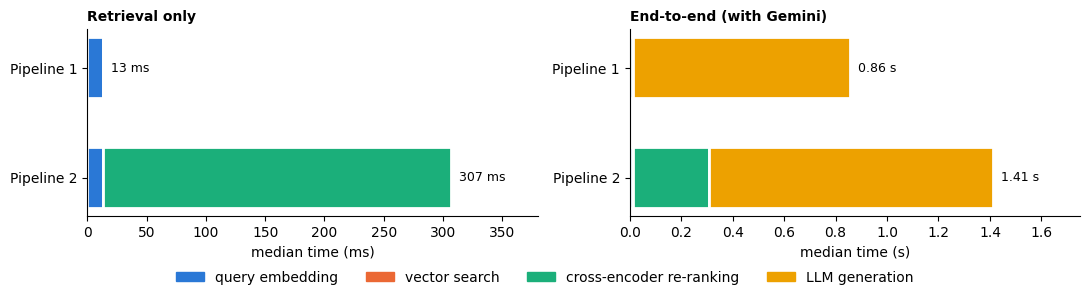

In [43]:
# Where does the time go? Left: retrieval only (ms). Right: end-to-end with generation (s).
STAGE_COLORS = {"query embedding": "#2a78d6", "vector search": "#eb6834",
                "cross-encoder re-ranking": "#1baf7a", "LLM generation": "#eda100"}
med = {c: np.median(stage_times[c]) for c in ["embed_ms", "search_ms", "rerank_ms"]}
gen = {p: np.median(v) for p, v in llm_ms.items()}
bars = {
    "Pipeline 1": {"query embedding": med["embed_ms"], "vector search": med["search_ms"],
                   "cross-encoder re-ranking": 0, "LLM generation": gen["Pipeline 1"]},
    "Pipeline 2": {"query embedding": med["embed_ms"], "vector search": med["search_ms"],
                   "cross-encoder re-ranking": med["rerank_ms"], "LLM generation": gen["Pipeline 2"]},
}

fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
for ax, include_llm, unit, scale in [(axes[0], False, "ms", 1), (axes[1], True, "s", 1000)]:
    for y, (pipeline, parts) in enumerate(bars.items()):
        left = 0
        for stage, value in parts.items():
            if stage == "LLM generation" and not include_llm:
                continue
            ax.barh(y, value / scale, left=left, color=STAGE_COLORS[stage], edgecolor="white", linewidth=2, height=0.55)
            left += value / scale
        ax.text(left, y, f"  {left:.0f} {unit}" if unit == "ms" else f"  {left:.2f} {unit}", va="center", fontsize=9)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(list(bars))
    ax.invert_yaxis()
    ax.set_xlabel(f"median time ({unit})")
    ax.set_title("Retrieval only" if not include_llm else "End-to-end (with Gemini)", loc="left", fontweight="bold", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(0, ax.get_xlim()[1] * 1.18)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in STAGE_COLORS.values()]
fig.legend(handles, list(STAGE_COLORS), loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "latency.png"), dpi=150, bbox_inches="tight")
plt.show()

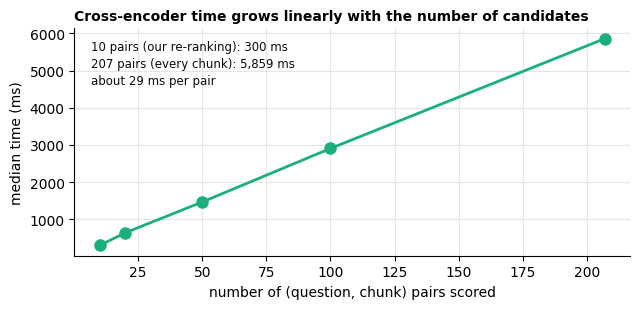

,pairs,ms,ms_per_pair
0,10,299.51,29.95
1,20,638.71,31.94
2,50,1466.05,29.32
3,100,2906.50,29.07
4,207,5859.27,28.31


In [44]:
# Cross-encoder cost vs number of candidates: it should grow linearly with the number of pairs
scaling_questions = test_questions[:5]
rows = []
for k_pairs in [10, 20, 50, 100, len(chunks)]:
    for q in scaling_questions:
        candidates = retrieve(q, k=k_pairs)
        pairs = [(q, t) for t in candidates["text"]]
        cross_encoder.predict(pairs[:5], show_progress_bar=False)              # warm-up
        start = time.perf_counter()
        cross_encoder.predict(pairs, show_progress_bar=False)
        rows.append({"pairs": k_pairs, "ms": 1000 * (time.perf_counter() - start)})
ce_scaling = pd.DataFrame(rows).groupby("pairs")["ms"].median().reset_index()
ce_scaling["ms_per_pair"] = ce_scaling["ms"] / ce_scaling["pairs"]
ce_scaling.round(2).to_csv(os.path.join(RESULTS_DIR, "ce_scaling.csv"), index=False)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(ce_scaling["pairs"], ce_scaling["ms"], color="#1baf7a", linewidth=2, marker="o", markersize=8)
first, last = ce_scaling.iloc[0], ce_scaling.iloc[-1]
note = (f"{first.pairs:.0f} pairs (our re-ranking): {first.ms:.0f} ms\n"
        f"{last.pairs:.0f} pairs (every chunk): {last.ms:,.0f} ms\n"
        f"about {ce_scaling['ms_per_pair'].median():.0f} ms per pair")
ax.text(0.03, 0.95, note, transform=ax.transAxes, va="top", fontsize=8.5, color="#0b0b0b", linespacing=1.4)
ax.set_xlabel("number of (question, chunk) pairs scored")
ax.set_ylabel("median time (ms)")
ax.set_title("Cross-encoder time grows linearly with the number of candidates", loc="left", fontsize=10, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e6e5e0")
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "ce_scaling.png"), dpi=150)
plt.show()
ce_scaling.round(2)